# CT Reconstruction: Backprojection and Filtered Backprojection

This notebook is a companion to the CT/CBCT hardware and reconstruction lecture.
It lets you generate your own sinograms and reconstruct them, so you can see —
rather than just be told — why plain backprojection blurs, why the ramp filter
fixes it, why that filter increases noise, and what "sharper vs softer" kernels
actually trade off.

**How to use it:** run each cell in order (Shift+Enter). The cells with sliders
are interactive — change the values and re-run, or just drag the slider if it
updates automatically. You don't need to understand the plotting code; focus on
what changes in the images and plots.

**Sections:**
1. Setup and a test object (the Shepp-Logan phantom)
2. Building a sinogram (the forward problem)
3. Plain backprojection — and why it blurs
4. The 1/r blur, made visible with a single point
5. Filtered backprojection — fixing the blur
6. Filter choice: resolution vs noise
7. How many projection angles do you actually need?
8. Put it all together: one interactive explorer


## 1. Setup

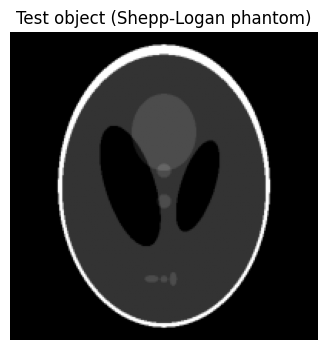

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.data import shepp_logan_phantom
from skimage.transform import radon, iradon, rescale
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown, Checkbox
import ipywidgets as widgets

plt.rcParams["figure.facecolor"] = "white"
np.random.seed(0)

# The Shepp-Logan phantom is a standard synthetic test object for CT research:
# an ellipse representing the skull, with smaller ellipses inside representing
# ventricles and small lesions of differing contrast. It is not a real patient,
# but it is designed to stress-test reconstruction algorithms.
phantom = shepp_logan_phantom()
phantom = rescale(phantom, 0.5, mode="reflect", channel_axis=None)  # smaller = faster

plt.figure(figsize=(4, 4))
plt.imshow(phantom, cmap="gray")
plt.title("Test object (Shepp-Logan phantom)")
plt.axis("off")
plt.show()


## 2. Building a sinogram (the forward problem)

Recall from the lecture: each column of the sinogram is one projection at one
angle — a line integral of the object along each ray. The `radon` function does
exactly this. Try changing `n_angles` below. What happens to the sinogram if
you only use a handful of angles?


In [2]:
def show_sinogram(n_angles=180):
    theta = np.linspace(0., 180., n_angles, endpoint=False)
    sinogram = radon(phantom, theta=theta)

    fig, ax = plt.subplots(1, 2, figsize=(9, 4))
    ax[0].imshow(phantom, cmap="gray")
    ax[0].set_title("Object")
    ax[0].axis("off")

    ax[1].imshow(sinogram, cmap="gray", aspect="auto",
                 extent=(0, 180, sinogram.shape[0], 0))
    ax[1].set_title(f"Sinogram ({n_angles} angles)")
    ax[1].set_xlabel(r"Angle $\theta$ (degrees)")
    ax[1].set_ylabel(r"Detector position $l$")
    plt.tight_layout()
    plt.show()

interact(show_sinogram, n_angles=IntSlider(min=2, max=360, step=1, value=180,
                                            description="n_angles"));


interactive(children=(IntSlider(value=180, description='n_angles', max=360, min=2), Output()), _dom_classes=('…

## 3. Plain backprojection — and why it blurs

Now reconstruct using **unfiltered** backprojection: smear each projection
back along its ray, and add all the angles together (`filter_name=None`).
This is exactly the "spoke" picture from the lecture.


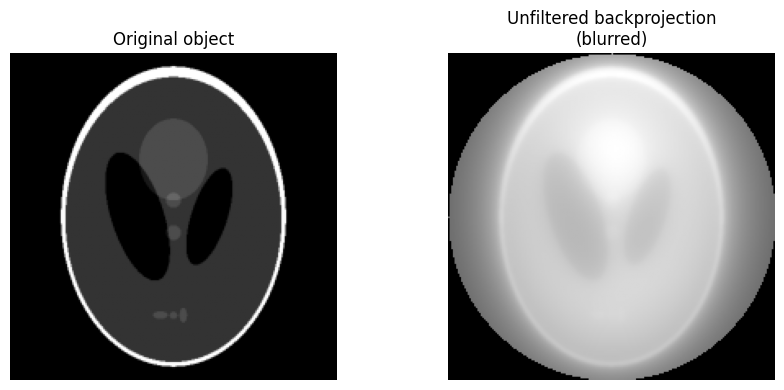

In [3]:
theta_full = np.linspace(0., 180., max(phantom.shape), endpoint=False)
sinogram_full = radon(phantom, theta=theta_full)

recon_unfiltered = iradon(sinogram_full, theta=theta_full, filter_name=None)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(phantom, cmap="gray")
ax[0].set_title("Original object")
ax[0].axis("off")

ax[1].imshow(recon_unfiltered, cmap="gray")
ax[1].set_title("Unfiltered backprojection\n(blurred)")
ax[1].axis("off")
plt.tight_layout()
plt.show()


Notice the shape is recognisable, but everything looks smeared and
low-contrast, as though a soft glow has been laid over the image. That glow
is the 1/r blur described in the lecture: every point in the true image has
been spread out over the whole reconstruction, with brightness falling off
as 1/r from the point.

## 4. The 1/r blur, made visible with a single point

The clearest way to see the 1/r effect is to reconstruct a single point
source rather than a full phantom. Backproject it and look at how the
brightness falls off with distance from the centre — it should follow a
1/r curve.


In [4]:
def point_source_blur(n_angles=180):
    point_img = np.zeros_like(phantom)
    c = phantom.shape[0] // 2
    point_img[c, c] = 1.0

    theta = np.linspace(0., 180., n_angles, endpoint=False)
    sino_pt = radon(point_img, theta=theta)
    bp_pt = iradon(sino_pt, theta=theta, filter_name=None)

    # radial profile: average brightness at each distance from the centre
    yy, xx = np.indices(bp_pt.shape)
    r = np.sqrt((xx - c) ** 2 + (yy - c) ** 2)
    r_int = r.astype(int)
    radial_mean = np.bincount(r_int.ravel(), bp_pt.ravel()) / np.maximum(
        np.bincount(r_int.ravel()), 1)

    r_vals = np.arange(1, min(60, len(radial_mean)))
    fitted_1_over_r = radial_mean[1] * r_vals[0] / r_vals  # scaled 1/r curve

    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    ax[0].imshow(bp_pt, cmap="gray")
    ax[0].set_title(f"Backprojected point\n({n_angles} angles)")
    ax[0].axis("off")

    ax[1].imshow(np.log(bp_pt + 1e-3), cmap="gray")
    ax[1].set_title("Same image, log scale\n(spokes visible at low n_angles)")
    ax[1].axis("off")

    ax[2].plot(r_vals, radial_mean[1:len(r_vals) + 1], label="measured", lw=2)
    ax[2].plot(r_vals, fitted_1_over_r, "--", label=r"$1/r$ reference", lw=2)
    ax[2].set_xlabel("distance from point, r (pixels)")
    ax[2].set_ylabel("mean brightness")
    ax[2].set_title("Radial brightness falloff")
    ax[2].legend()
    plt.tight_layout()
    plt.show()

interact(point_source_blur, n_angles=IntSlider(min=4, max=360, step=2, value=180,
                                                description="n_angles"));


interactive(children=(IntSlider(value=180, description='n_angles', max=360, min=4, step=2), Output()), _dom_cl…

Try dragging `n_angles` down to something small (8-16). In the log-scale
image you should see individual spokes radiating from the point, exactly
like the "2, 4, 8 projections" panel in the lecture slides. As you increase
`n_angles`, the spokes merge into the smooth glow, and the measured curve
should sit close to the 1/r reference line.

## 5. Filtered backprojection — fixing the blur

`iradon` can apply a ramp filter to each projection before backprojecting,
exactly as described in the lecture: multiply by `|k|` in frequency space
before smearing back. Compare unfiltered vs ramp-filtered reconstruction of
the full phantom.


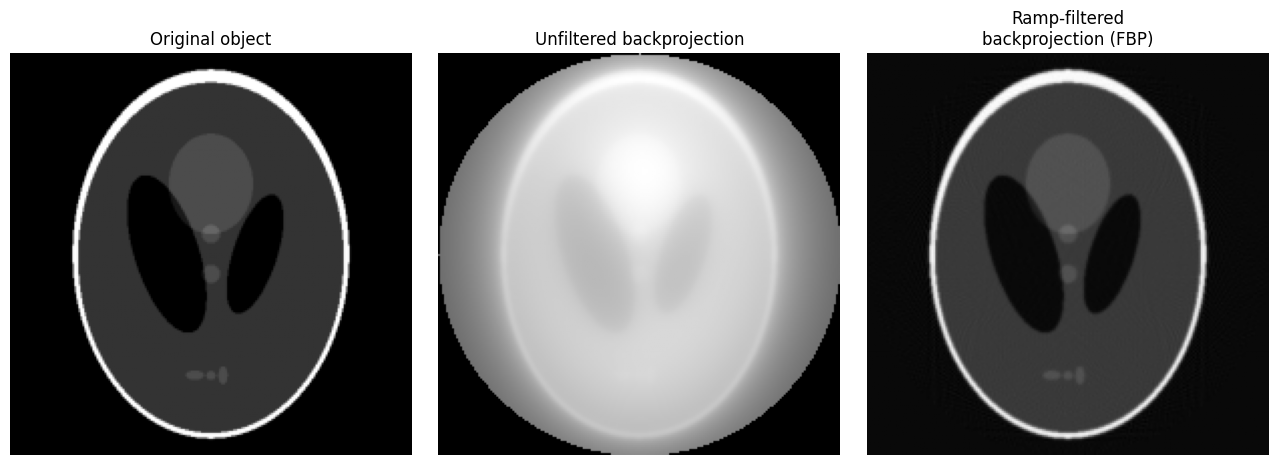

Pixel-value range, unfiltered: 0.000 to 58.071
Pixel-value range, ramp FBP:   -0.041 to 1.023


In [5]:
recon_ramp = iradon(sinogram_full, theta=theta_full, filter_name="ramp")

fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
ax[0].imshow(phantom, cmap="gray")
ax[0].set_title("Original object")
ax[0].axis("off")

ax[1].imshow(recon_unfiltered, cmap="gray")
ax[1].set_title("Unfiltered backprojection")
ax[1].axis("off")

ax[2].imshow(recon_ramp, cmap="gray")
ax[2].set_title("Ramp-filtered\nbackprojection (FBP)")
ax[2].axis("off")
plt.tight_layout()
plt.show()

print("Pixel-value range, unfiltered: %.3f to %.3f" %
      (recon_unfiltered.min(), recon_unfiltered.max()))
print("Pixel-value range, ramp FBP:   %.3f to %.3f" %
      (recon_ramp.min(), recon_ramp.max()))


The ramp-filtered image should look far closer to the original object:
sharper edges and much better contrast between the small internal features.
Look also at the printed pixel value ranges — unfiltered backprojection
compresses everything into a narrow, washed-out range, while the filtered
version recovers something closer to the object's real contrast.

You can also look directly at what the ramp filter does to a single
projection profile:

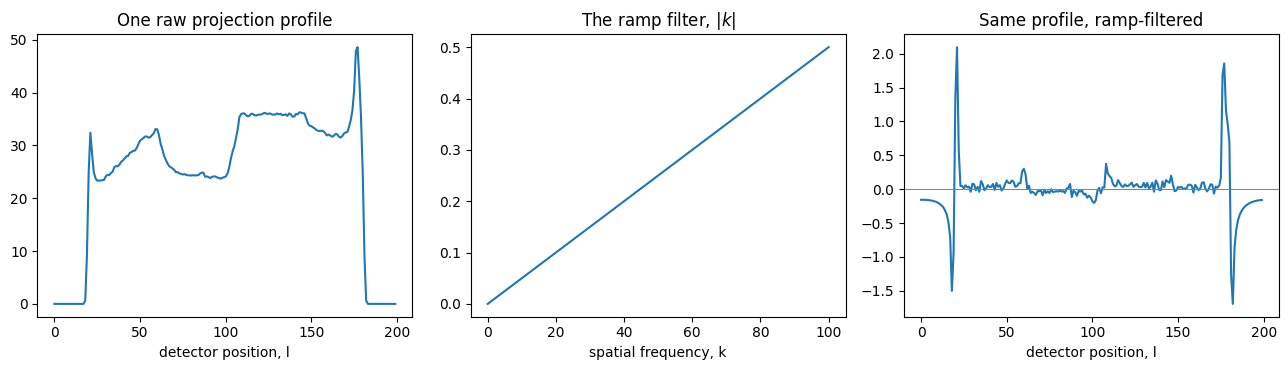

In [6]:
from scipy.fft import rfft, irfft, rfftfreq

def ramp_filter_1d(profile):
    n = len(profile)
    freqs = rfftfreq(n)
    spectrum = rfft(profile)
    ramp = np.abs(freqs)               # the ramp filter itself, |k|
    filtered_spectrum = spectrum * ramp
    return irfft(filtered_spectrum, n=n), ramp

angle_index = sinogram_full.shape[1] // 4   # pick one projection to inspect
profile = sinogram_full[:, angle_index]
filtered_profile, ramp_shape = ramp_filter_1d(profile)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].plot(profile)
ax[0].set_title("One raw projection profile")
ax[0].set_xlabel("detector position, l")

ax[1].plot(ramp_shape)
ax[1].set_title(r"The ramp filter, $|k|$")
ax[1].set_xlabel("spatial frequency, k")

ax[2].plot(filtered_profile)
ax[2].set_title("Same profile, ramp-filtered")
ax[2].set_xlabel("detector position, l")
ax[2].axhline(0, color="grey", lw=0.7)
plt.tight_layout()
plt.show()


Look for the negative dips either side of each rising or falling edge in
the filtered profile — that's the "negative lobes" behaviour described in
the lecture. Those negative values are what cancel the 1/r tails when many
filtered projections are backprojected together.

## 6. Filter choice: resolution vs noise

The pure ramp filter (`ram-lak`) keeps all high frequencies, which is why it
sharpens best but also amplifies noise the most. Softer kernels roll off the
high frequencies to trade some sharpness for lower noise. Here we add
noise to the sinogram (simulating a noisier acquisition, e.g. lower dose) and
compare filters.


In [7]:
def compare_filters(noise_level=0.0, filter_name="ramp"):
    rng = np.random.default_rng(1)
    noisy_sino = sinogram_full + rng.normal(0, noise_level, sinogram_full.shape)

    recon = iradon(noisy_sino, theta=theta_full,
                    filter_name=(None if filter_name == "none" else filter_name))

    # Unfiltered backprojection sits on a completely different intensity
    # scale to the filtered/original image (its values can run into the
    # tens, not 0-1), so a fixed vmin/vmax would saturate it to solid white.
    # Scale each reconstruction to its own 1st-99th percentile instead, so
    # you're always looking at its *contrast*, not an arbitrary absolute
    # brightness.
    vmin, vmax = np.percentile(recon, [1, 99])

    fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
    ax[0].imshow(noisy_sino, cmap="gray", aspect="auto")
    ax[0].set_title(f"Sinogram (noise sd = {noise_level:.2f})")
    ax[0].axis("off")

    ax[1].imshow(recon, cmap="gray", vmin=vmin, vmax=vmax)
    ax[1].set_title(f"Reconstruction, filter = {filter_name}")
    ax[1].axis("off")
    plt.tight_layout()
    plt.show()

interact(compare_filters,
         noise_level=FloatSlider(min=0.0, max=0.5, step=0.02, value=0.1,
                                  description="noise sd"),
         filter_name=Dropdown(options=["none", "ramp", "shepp-logan", "cosine",
                                        "hamming", "hann"],
                               value="ramp", description="kernel"));


interactive(children=(FloatSlider(value=0.1, description='noise sd', max=0.5, step=0.02), Dropdown(description…

Set `noise_level` to something moderate (0.1-0.2) and flip between
`ramp` and `hann`. `ramp` (the pure, unwindowed filter — equivalent to
"ram-lak" in the lecture) should look sharper but grainier; `hann` should
look smoother with less visible noise but slightly softer edges. This is the
same trade-off as the "sharp kernel for lung/bone vs soft kernel for
abdomen/brain" slide, just reproduced on noisy data instead of two different
anatomical sites.

**Something to try:** at `noise_level = 0`, do `ramp` and `hann` look very
different? Why might the choice of kernel matter much less when there's very
little noise to begin with?

## 7. How many projection angles do you actually need?

Fewer angles means a faster (or lower-dose) scan, but incomplete sampling of
the sinogram. This reproduces the "2, 4, 8, 16, 64 projections" panel from
the lecture, but with filtering switched on or off so you can see both
effects at once.


In [ ]:
def angles_vs_quality(n_angles=180, filtered=True):
    theta = np.linspace(0., 180., n_angles, endpoint=False)
    sino = radon(phantom, theta=theta)
    recon = iradon(sino, theta=theta,
                    filter_name=("ramp" if filtered else None))

    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(recon, cmap="gray")
    plt.title(f"{n_angles} angles, {'filtered' if filtered else 'unfiltered'}")
    plt.axis("off")
    plt.show()

interact(angles_vs_quality,
         n_angles=IntSlider(min=2, max=360, step=1, value=60, description="n_angles"),
         filtered=Checkbox(value=True, description="apply ramp filter"));


interactive(children=(IntSlider(value=60, description='n_angles', max=360, min=2), Checkbox(value=True, descri…

With `filtered` unticked and a small number of angles, look for the
streaky, spoke-like artefacts radiating from bright features — this is the
same undersampling pattern as the point-source spokes in Section 4, just now
affecting a realistic object. Note that filtering does **not** fix
undersampling artefacts the way it fixes the 1/r blur — those are two
different problems. The lecture's "minimum 180°" rule is about *angular
range*, not how many angles you take within that range, but sparse angles
within 180° still show up as streaks here.

## 8. Put it all together: one interactive explorer

A single view combining sinogram, reconstruction, and radial noise/streak
behaviour, so you can explore the full parameter space at once. This is a
good cell to leave running while discussing the trade-offs as a group.


In [9]:
def full_explorer(n_angles=90, filter_name="ramp", noise_sd=0.0):
    theta = np.linspace(0., 180., n_angles, endpoint=False)
    rng = np.random.default_rng(2)
    sino = radon(phantom, theta=theta)
    sino_noisy = sino + rng.normal(0, noise_sd, sino.shape)

    recon = iradon(sino_noisy, theta=theta,
                    filter_name=(None if filter_name == "none" else filter_name))

    # Unfiltered backprojection sits on a completely different intensity
    # scale to the filtered/original image (its values can run into the
    # tens, not 0-1), so a fixed vmin/vmax would saturate it to solid white.
    # Scale each reconstruction to its own 1st-99th percentile instead, so
    # you're always looking at its *contrast*, not an arbitrary absolute
    # brightness.
    vmin, vmax = np.percentile(recon, [1, 99])

    fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
    ax[0].imshow(phantom, cmap="gray")
    ax[0].set_title("Original object")
    ax[0].axis("off")

    ax[1].imshow(sino_noisy, cmap="gray", aspect="auto")
    ax[1].set_title(f"Sinogram\n({n_angles} angles, noise sd={noise_sd:.2f})")
    ax[1].axis("off")

    ax[2].imshow(recon, cmap="gray", vmin=vmin, vmax=vmax)
    ax[2].set_title(f"Reconstruction\n(filter={filter_name})")
    ax[2].axis("off")
    plt.tight_layout()
    plt.show()

interact(full_explorer,
         n_angles=IntSlider(min=2, max=360, step=1, value=90, description="n_angles"),
         filter_name=Dropdown(options=["none", "ramp", "shepp-logan", "cosine",
                                        "hamming", "hann"],
                               value="ramp", description="kernel"),
         noise_sd=FloatSlider(min=0.0, max=0.5, step=0.02, value=0.05,
                               description="noise sd"));


interactive(children=(IntSlider(value=90, description='n_angles', max=360, min=2), Dropdown(description='kerne…

### Questions to work through

1. Set `filter_name = "none"` and `n_angles = 360`, `noise_sd = 0`. Why is the
   image still blurry even with a full set of noise-free angles?
2. Now set `filter_name = "ramp"`, keeping everything else the same. What
   changed, and why?
3. Push `noise_sd` up to 0.3 with `filter_name = "ramp"`. Then switch to
   `"hann"`. What's the trade-off you're seeing?
4. Drop `n_angles` to 10 with `filter_name = "ramp"` and `noise_sd = 0`. Is
   this artefact the same thing as the 1/r blur from Section 3-4? (It isn't —
   see the note at the end of Section 7.)

### Limitations of this notebook

- `radon`/`iradon` in `scikit-image` implement the **parallel-beam** case
  only, which matches the simplified explanation in the lecture. Real CT
  scanners use fan-beam geometry (slides 45-46), and CBCT uses cone-beam FDK
  reconstruction (slides 51-52) — the same filtering principle, but with the
  extra geometric weighting described in the lecture, which isn't reproduced
  here.
- The "noise" added here is simple Gaussian noise on the sinogram. Real
  detector noise is closer to Poisson (photon-counting) statistics, and its
  magnitude depends on dose.
